In [44]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, filename):
    fig.savefig(
        FIGURE_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    print(f"Saved: {filename}")

DATA_PATH = (PROJECT_ROOT / 'data' / 'processed' / 'monthly_features_seasonal.csv')
df = pd.read_csv(DATA_PATH, dtype={'STATION':str})

features_A = [
    "TEMP_MEAN",
    "DEWP_MEAN",
    "WDSP_MEAN",
    "TEMP_MIN_MEAN",
    "TEMP_MAX_MEAN",
    "MONTH_COS",
    "MONTH_SIN"
]

features_B = features_A + [
    "PRCP_LAG_0",
    "PRCP_LAG_1",
    "PRCP_LAG_2"
]

target = 'TARGET_NEXT_MONTH'

print("Dataset:", df.shape)
print("Stations:", df["STATION"].nunique())
print("Feature Set A:", len(features_A))
print("Feature Set B:", len(features_B))

Dataset: (1768, 45)
Stations: 6
Feature Set A: 7
Feature Set B: 10


In [8]:
stations = sorted(df['STATION'].unique())
nested_splits = []

for outer_station in stations:
    outer_train = df[df['STATION'] != outer_station]
    outer_test = df[df['STATION'] == outer_station]

    inner_splits = []
    inner_stations = sorted(outer_train['STATION'].unique())

    for station in inner_stations:
        inner_train = outer_train[outer_train['STATION'] != station]
        inner_val = outer_train[outer_train['STATION'] == station]
        inner_splits.append({
            'val_station': station,
            'train_idx': inner_train.index.to_numpy(),
            'val_idx': inner_val.index.to_numpy()
        })

    nested_splits.append({
        "test_station": outer_station,
        "train_idx": outer_train.index.to_numpy(),
        "test_idx": outer_test.index.to_numpy(),
        "inner_splits": inner_splits
    })

print("Outer folds:", len(nested_splits))
print("Inner folds per outer fold:", [len(fold['inner_splits']) for fold in nested_splits])



Outer folds: 6
Inner folds per outer fold: [5, 5, 5, 5, 5, 5]


In [14]:
from src.models.ridge_gd import RidgeRegressionGD

lambda_grid = [0.01, 0.1, 1.0, 10.0, 100.0, 300.0, 1000.0, 3000.0]

def tune_ridge_inner_loso(df, outer_fold, feature_cols, target_col, lambda_grid, learning_rate=0.01, iterations=3000):
    
    results = []

    for lambda_value in lambda_grid:
        fold_maes = []
        for inner in outer_fold['inner_splits']:
            inner_train = df.loc[inner['train_idx']]
            inner_val = df.loc[inner['val_idx']]
            X_train = inner_train[feature_cols].to_numpy(dtype=float)
            X_val = inner_val[feature_cols].to_numpy(dtype=float)
            y_train = inner_train[target_col].to_numpy(dtype=float)
            y_val = inner_val[target_col].to_numpy(dtype=float)

            train_mean = X_train.mean(axis=0)
            train_std = X_train.std(axis=0)
            train_std[train_std == 0] = 1.0

            X_train_scaled = (X_train - train_mean) / train_std
            X_val_scaled = (X_val - train_mean) / train_std

            model = RidgeRegressionGD(
                learning_rate=learning_rate,
                iterations=iterations,
                lambda_=lambda_value
            )

            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_val_scaled)

            if not np.isfinite(y_pred).all():
                raise ValueError(
                    f"Non-finite predictions for lambda={lambda_value}"
                )

            mae = np.mean(np.abs(y_val - y_pred))
            fold_maes.append(mae)

        results.append({
            "lambda": lambda_value,
            "mean_inner_mae": np.mean(fold_maes),
            "std_inner_mae": np.std(fold_maes),
            "fold_maes": fold_maes
        })

    tuning_df = pd.DataFrame(results).sort_values('lambda')
    best_idx = tuning_df["mean_inner_mae"].idxmin()
    best_lambda = float(tuning_df.loc[best_idx, "lambda"])

    return best_lambda, tuning_df


In [17]:
best_lambda_A, tuning_A = tune_ridge_inner_loso(
    df=df,
    outer_fold=nested_splits[0],
    feature_cols=features_A,
    target_col=target,
    lambda_grid=lambda_grid
)
display(tuning_A)
print("Selected lambda:", best_lambda_A)



,lambda,mean_inner_mae,std_inner_mae,fold_maes
0,0.01,8.827189,1.316851,"[7.777251171535414, 8.949777070443389, 11.3308..."
1,0.10,8.826782,1.316786,"[7.77695799902036, 8.948771425803361, 11.33052..."
2,1.00,8.822735,1.316143,"[7.7740427320446654, 8.93877003623611, 11.3269..."
3,10.00,8.785891,1.310546,"[7.746455314203988, 8.851426025655957, 11.2933..."
4,100.00,8.601786,1.286034,"[7.574124407568941, 8.549480303647236, 11.0894..."
5,300.00,8.523344,1.278996,"[7.440595605709258, 8.683223625939727, 10.9382..."
6,1000.00,8.557602,1.312290,"[7.392523089137041, 9.23181972755689, 10.83068..."
7,3000.00,8.651720,1.335513,"[7.510942527533399, 9.57802750235302, 10.83812..."


Selected lambda: 300.0


In [26]:
def evaluate_ridge_outer_fold(
    df,
    outer_fold,
    feature_cols,
    target_col,
    selected_lambda,
    feature_set_name,
    learning_rate=0.01,
    iterations=3000
):
    outer_train = df.loc[outer_fold["train_idx"]]
    outer_test = df.loc[outer_fold["test_idx"]]

    X_train = outer_train[feature_cols].to_numpy(dtype=float)
    X_test = outer_test[feature_cols].to_numpy(dtype=float)

    y_train = outer_train[target_col].to_numpy(dtype=float)
    y_test = outer_test[target_col].to_numpy(dtype=float)

    train_mean = X_train.mean(axis=0)
    train_std = X_train.std(axis=0)
    train_std[train_std == 0] = 1.0

    X_train_scaled = (X_train - train_mean) / train_std
    X_test_scaled = (X_test - train_mean) / train_std

    outer_model = RidgeRegressionGD(
        learning_rate=learning_rate,
        iterations=iterations,
        lambda_=selected_lambda
    )

    outer_model.fit(X_train_scaled, y_train)
    y_pred = outer_model.predict(X_test_scaled)

    if not np.isfinite(y_pred).all():
        raise ValueError("Non-finite Ridge predictions.")

    errors = y_test - y_pred
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    ss_res = np.sum(errors ** 2)
    ss_tot = np.sum((y_test - y_test.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    zero_mae = np.mean(np.abs(y_test))
    zero_rmse = np.sqrt(np.mean((y_test ** 2)))

    return {
        "station": outer_fold["test_station"],
        "feature_set": feature_set_name,
        "lambda": selected_lambda,
        "test_months": len(y_test),
        "mae": float(mae),
        "rmse": float(rmse),
        "r2": float(r2),
        "zero_mae": float(zero_mae),
        "zero_rmse": float(zero_rmse),
        "negative_predictions": int(np.sum(y_pred < 0))
    }

In [30]:
feature_sets = {
    'A': features_A,
    'B': features_B
}

all_results = []
all_tuning_results = []

for feature_name, feature_cols in feature_sets.items():
    print(f"Feature Set {feature_name}")
    print(f"{'-' * 55}")

    for fold_number, outer_fold in enumerate(nested_splits, start=1):
        selected_lambda, tuning_table = tune_ridge_inner_loso(
            df=df,
            outer_fold=outer_fold,
            feature_cols=feature_cols,
            target_col=target,
            lambda_grid=lambda_grid
        )

        result = evaluate_ridge_outer_fold(
            df=df,
            outer_fold=outer_fold,
            feature_cols=feature_cols,
            target_col=target,
            selected_lambda=selected_lambda,
            feature_set_name=feature_name
        )

        result['fold'] = fold_number
        all_results.append(result)

        tuning_table = tuning_table.copy()
        tuning_table['feature_set'] = feature_name
        tuning_table['outer_fold'] = fold_number
        tuning_table['test_station'] = outer_fold['test_station']

        all_tuning_results.append(tuning_table)

        print(
            f"Fold {fold_number} | "
            f"Station: {result['station']} | "
            f"λ={selected_lambda:g} | "
            f"MAE={result['mae']:.4f} | "
            f"RMSE={result['rmse']:.4f} | "
            f"R²={result['r2']:.4f}"
        )

ridge_results_df = pd.DataFrame(all_results)

ridge_tuning_df = pd.concat(all_tuning_results, ignore_index=True)

display(
    ridge_results_df[
        [
            "feature_set",
            "fold",
            "station",
            "lambda",
            "test_months",
            "mae",
            "rmse",
            "r2",
            "zero_mae",
            "zero_rmse",
            "negative_predictions"
        ]
    ].round(4)
)

Feature Set A
-------------------------------------------------------
Fold 1 | Station: 41184099999 | λ=300 | MAE=9.1708 | RMSE=18.8856 | R²=0.0526
Fold 2 | Station: 41194099999 | λ=300 | MAE=7.4284 | RMSE=13.4915 | R²=0.0663
Fold 3 | Station: 41196099999 | λ=300 | MAE=9.5772 | RMSE=19.9890 | R²=0.0214
Fold 4 | Station: 41198099999 | λ=300 | MAE=11.0889 | RMSE=35.5041 | R²=0.0068
Fold 5 | Station: 41217099999 | λ=300 | MAE=7.6191 | RMSE=13.5707 | R²=-0.0362
Fold 6 | Station: 41218099999 | λ=100 | MAE=8.1639 | RMSE=17.4679 | R²=-0.0436
Feature Set B
-------------------------------------------------------
Fold 1 | Station: 41184099999 | λ=300 | MAE=9.1568 | RMSE=18.8150 | R²=0.0597
Fold 2 | Station: 41194099999 | λ=300 | MAE=7.3007 | RMSE=13.4946 | R²=0.0659
Fold 3 | Station: 41196099999 | λ=300 | MAE=9.5660 | RMSE=19.8880 | R²=0.0313
Fold 4 | Station: 41198099999 | λ=300 | MAE=11.5810 | RMSE=35.7607 | R²=-0.0076
Fold 5 | Station: 41217099999 | λ=300 | MAE=7.3696 | RMSE=13.5430 | R²=-0.0

,feature_set,fold,station,lambda,test_months,mae,rmse,r2,zero_mae,zero_rmse,negative_predictions
0,A,1,41184099999,300.0,297,9.1708,18.8856,0.0526,7.6739,20.8652,0
1,A,2,41194099999,300.0,313,7.4284,13.4915,0.0663,4.6572,14.7186,0
2,A,3,41196099999,300.0,295,9.5772,19.9890,0.0214,7.7741,21.6505,0
3,A,4,41198099999,300.0,272,11.0889,35.5041,0.0068,9.0011,36.7456,4
4,A,5,41217099999,300.0,302,7.6191,13.5707,-0.0362,3.4399,13.7685,0
5,A,6,41218099999,100.0,289,8.1639,17.4679,-0.0436,3.7836,17.5128,2
6,B,1,41184099999,300.0,297,9.1568,18.8150,0.0597,7.6739,20.8652,0
7,B,2,41194099999,300.0,313,7.3007,13.4946,0.0659,4.6572,14.7186,0
8,B,3,41196099999,300.0,295,9.5660,19.8880,0.0313,7.7741,21.6505,0
9,B,4,41198099999,300.0,272,11.5810,35.7607,-0.0076,9.0011,36.7456,4


In [ ]:
comparison_df = (
    ridge_results_df
    .groupby("feature_set")
    .agg(
        mean_mae=("mae", "mean"),
        mean_rmse=("rmse", "mean"),
        mean_r2=("r2", "mean"),
        mean_zero_mae=("zero_mae", "mean"),
        mean_zero_rmse=("zero_rmse", "mean")
    )
)

display(comparison_df.round(4))


,mean_mae,mean_rmse,mean_r2,mean_zero_mae,mean_zero_rmse
feature_set,,,,,
A,8.8414,19.8181,0.0112,6.055,20.8769
B,8.8251,19.8165,0.0137,6.055,20.8769


In [33]:
# Compare A and B on the same held-out stations
paired = ridge_results_df.pivot(
    index="station",
    columns="feature_set",
    values=["mae", "rmse", "r2"]
)

paired_comparison = pd.DataFrame({
    "station": paired.index,
    "mae_A": paired[("mae", "A")].values,
    "mae_B": paired[("mae", "B")].values,
    "rmse_A": paired[("rmse", "A")].values,
    "rmse_B": paired[("rmse", "B")].values
})

# Positive difference means Set B performs better
paired_comparison["mae_gain_B"] = (
    paired_comparison["mae_A"] -
    paired_comparison["mae_B"]
)

paired_comparison["rmse_gain_B"] = (
    paired_comparison["rmse_A"] -
    paired_comparison["rmse_B"]
)

display(paired_comparison.round(4))

print(
    "Stations where B improves MAE:",
    (paired_comparison["mae_gain_B"] > 0).sum(),
    "/ 6"
)

print(
    "Stations where B improves RMSE:",
    (paired_comparison["rmse_gain_B"] > 0).sum(),
    "/ 6"
)

print(
    "Mean MAE gain:",
    round(paired_comparison["mae_gain_B"].mean(), 4)
)

print(
    "Mean RMSE gain:",
    round(paired_comparison["rmse_gain_B"].mean(), 4)
)


,station,mae_A,mae_B,rmse_A,rmse_B,mae_gain_B,rmse_gain_B
0,41184099999,9.1708,9.1568,18.8856,18.8150,0.0140,0.0706
1,41194099999,7.4284,7.3007,13.4915,13.4946,0.1277,-0.0031
2,41196099999,9.5772,9.5660,19.9890,19.8880,0.0112,0.1010
3,41198099999,11.0889,11.5810,35.5041,35.7607,-0.4922,-0.2567
4,41217099999,7.6191,7.3696,13.5707,13.5430,0.2495,0.0277
5,41218099999,8.1639,7.9763,17.4679,17.3978,0.1875,0.0701


Stations where B improves MAE: 5 / 6
Stations where B improves RMSE: 4 / 6
Mean MAE gain: 0.0163
Mean RMSE gain: 0.0016


In [34]:
def evaluate_monthly_climatology(df, outer_fold, target_col):
    """
    Calendar-month climatology baseline.

    Monthly averages are learned only from the
    outer training stations.

    Uses target-month seasonality to predict
    next-month rainfall at the unseen station.
    """
    train_part = df.loc[outer_fold["train_idx"]]
    test_part = df.loc[outer_fold["test_idx"]]

    # Calculate the mean rainfall for each TARGET month
    monthly_means = train_part.groupby(
        "TARGET_MONTH"
    )[target_col].mean()

    # Use training global mean only as a fallback
    global_mean = train_part[target_col].mean()

    predictions = (
        test_part["TARGET_MONTH"]
        .map(monthly_means)
        .fillna(global_mean)
        .to_numpy(dtype=float)
    )

    y_test = test_part[target_col].to_numpy(dtype=float)

    errors = y_test - predictions

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    return {
        "station": outer_fold["test_station"],
        "test_months": len(y_test),
        "mae": float(mae),
        "rmse": float(rmse)
    }


In [37]:
climatology_results = []

for outer_fold in nested_splits:
    result = evaluate_monthly_climatology(
        df=df,
        outer_fold=outer_fold,
        target_col=target
    )

    climatology_results.append(result)

climatology_df = pd.DataFrame(climatology_results)

display(climatology_df.round(4))

print(
    "Mean Climatology MAE:",
    round(climatology_df["mae"].mean(), 4)
)

print(
    "Mean Climatology RMSE:",
    round(climatology_df["rmse"].mean(), 4)
)

assert len(climatology_df) == 6
assert climatology_df["test_months"].sum() == len(df)

assert climatology_df[["mae", "rmse"]].notna().all().all()

assert np.isfinite(
    climatology_df[["mae", "rmse"]].to_numpy()
).all()

print("Calendar-month climatology evaluation: PASSED")



,station,test_months,mae,rmse
0,41184099999,297,9.1352,18.4818
1,41194099999,313,7.2216,13.1992
2,41196099999,295,9.2087,19.7080
3,41198099999,272,10.5990,35.2242
4,41217099999,302,7.6017,13.7675
5,41218099999,289,7.7454,17.4753


Mean Climatology MAE: 8.5853
Mean Climatology RMSE: 19.6427
Calendar-month climatology evaluation: PASSED


In [38]:

# Compare climatology against Ridge B for identical stations
ridge_B = (
    ridge_results_df[
        ridge_results_df["feature_set"] == "B"
    ][["station", "mae", "rmse"]]
    .rename(columns={
        "mae": "ridge_B_mae",
        "rmse": "ridge_B_rmse"
    })
)

climatology_comparison = climatology_df[
    ["station", "mae", "rmse"]
].rename(columns={
    "mae": "clim_mae",
    "rmse": "clim_rmse"
})

station_comparison = climatology_comparison.merge(
    ridge_B,
    on="station",
    how="inner",
    validate="one_to_one"
)

# Positive values indicate climatology is better
station_comparison["clim_mae_gain"] = (
    station_comparison["ridge_B_mae"]
    - station_comparison["clim_mae"]
)

station_comparison["clim_rmse_gain"] = (
    station_comparison["ridge_B_rmse"]
    - station_comparison["clim_rmse"]
)

display(station_comparison.round(4))

print(
    "Climatology improves MAE:",
    (station_comparison["clim_mae_gain"] > 0).sum(),
    "/ 6 stations"
)

print(
    "Climatology improves RMSE:",
    (station_comparison["clim_rmse_gain"] > 0).sum(),
    "/ 6 stations"
)


,station,clim_mae,clim_rmse,ridge_B_mae,ridge_B_rmse,clim_mae_gain,clim_rmse_gain
0,41184099999,9.1352,18.4818,9.1568,18.8150,0.0216,0.3332
1,41194099999,7.2216,13.1992,7.3007,13.4946,0.0791,0.2953
2,41196099999,9.2087,19.7080,9.5660,19.8880,0.3573,0.1800
3,41198099999,10.5990,35.2242,11.5810,35.7607,0.9820,0.5365
4,41217099999,7.6017,13.7675,7.3696,13.5430,-0.2321,-0.2245
5,41218099999,7.7454,17.4753,7.9763,17.3978,0.2309,-0.0775


Climatology improves MAE: 5 / 6 stations
Climatology improves RMSE: 4 / 6 stations


Under nested leave-one-station-out evaluation, calendar-month climatology outperformed Ridge Regression with weather, seasonal, and rainfall-history features in most held-out stations. This suggests that the additional predictors provided limited generalization benefit over a simple seasonal baseline in the evaluated setting.

In [41]:
# Main results table
main_results = pd.DataFrame([
    {
        "Model": "Zero Baseline",
        "MAE (mm)": ridge_results_df[
            ridge_results_df["feature_set"] == "A"
        ]["zero_mae"].mean(),
        "RMSE (mm)": ridge_results_df[
            ridge_results_df["feature_set"] == "A"
        ]["zero_rmse"].mean()
    },
    {
        "Model": "Calendar-Month Climatology",
        "MAE (mm)": climatology_df["mae"].mean(),
        "RMSE (mm)": climatology_df["rmse"].mean()
    },
    {
        "Model": "Ridge - Feature Set A",
        "MAE (mm)": comparison_df.loc["A", "mean_mae"],
        "RMSE (mm)": comparison_df.loc["A", "mean_rmse"]
    },
    {
        "Model": "Ridge - Feature Set B",
        "MAE (mm)": comparison_df.loc["B", "mean_mae"],
        "RMSE (mm)": comparison_df.loc["B", "mean_rmse"]
    }
])

main_results = main_results.sort_values(
    "RMSE (mm)"
).reset_index(drop=True)

display(main_results.round(4))


,Model,MAE (mm),RMSE (mm)
0,Calendar-Month Climatology,8.5853,19.6427
1,Ridge - Feature Set B,8.8251,19.8165
2,Ridge - Feature Set A,8.8414,19.8181
3,Zero Baseline,6.0550,20.8769


In [43]:
rmse_comparison = (
    ridge_results_df
    .pivot(index="station", columns="feature_set", values="rmse")
    .rename(columns={"A": "Ridge A", "B": "Ridge B"})
)

clim_rmse = climatology_df.set_index("station")["rmse"]

zero_rmse = (
    ridge_results_df[
        ridge_results_df["feature_set"] == "A"
    ]
    .set_index("station")["zero_rmse"]
)

rmse_comparison["Climatology"] = clim_rmse
rmse_comparison["Zero Baseline"] = zero_rmse

rmse_comparison = rmse_comparison[
    ["Zero Baseline", "Climatology", "Ridge A", "Ridge B"]
]

display(rmse_comparison.round(4))



feature_set,Zero Baseline,Climatology,Ridge A,Ridge B
station,,,,
41184099999,20.8652,18.4818,18.8856,18.8150
41194099999,14.7186,13.1992,13.4915,13.4946
41196099999,21.6505,19.7080,19.9890,19.8880
41198099999,36.7456,35.2242,35.5041,35.7607
41217099999,13.7685,13.7675,13.5707,13.5430
41218099999,17.5128,17.4753,17.4679,17.3978


Saved: station_level_rmse_comparison


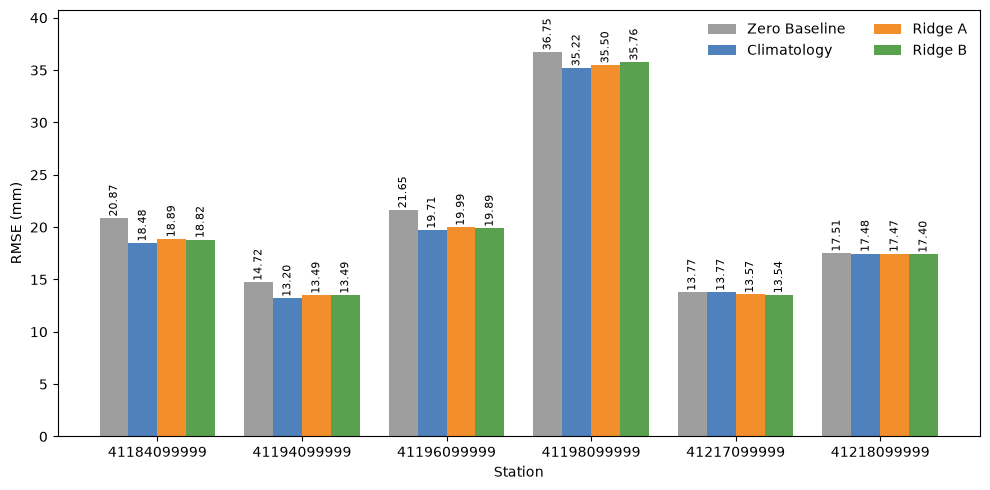

In [46]:
plot = rmse_comparison.copy()
stations = plot.index.astype(str)
models = plot.columns.to_list()

x = np.arange(len(stations))
width = 0.2

fig,ax = plt.subplots(figsize = (10,5))

colors = {
    "Zero Baseline": "#9e9e9e",
    "Climatology": "#4f81bd",
    "Ridge A": "#f28e2b",
    "Ridge B": "#59a14f"
}

for i, model in enumerate(models):
    values = plot[model].to_numpy()
    bars = ax.bar(
        x + (i - 1.5) * width,
        values,
        width=width,
        label=model,
        color=colors[model]
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.15,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels(stations, rotation=0)
ax.set_xlabel("Station")
ax.set_ylabel("RMSE (mm)")
ax.legend(frameon=False, ncol=2)
ax.set_ylim(0, plot.to_numpy().max() + 4)

plt.tight_layout()
save_figure(fig, "station_level_rmse_comparison")
plt.show()


Figure 1. Station-level RMSE comparison for Zero Baseline, calendar-month climatology, Ridge regression with Feature Set A, and Ridge regression with Feature Set B under leave-one-station-out evaluation.

In [49]:
mae_comparison = (
    ridge_results_df
    .pivot(index="station", columns="feature_set", values="mae")
    .rename(columns={"A": "Ridge A", "B": "Ridge B"})
)

mae_comparison["Climatology"] = (
    climatology_df.set_index("station")["mae"]
)

mae_comparison["Zero Baseline"] = (
    ridge_results_df[
        ridge_results_df["feature_set"] == "A"
    ].set_index("station")["zero_mae"]
)

mae_comparison = mae_comparison[
    ["Zero Baseline", "Climatology", "Ridge A", "Ridge B"]
]

display(mae_comparison.round(4))



feature_set,Zero Baseline,Climatology,Ridge A,Ridge B
station,,,,
41184099999,7.6739,9.1352,9.1708,9.1568
41194099999,4.6572,7.2216,7.4284,7.3007
41196099999,7.7741,9.2087,9.5772,9.5660
41198099999,9.0011,10.5990,11.0889,11.5810
41217099999,3.4399,7.6017,7.6191,7.3696
41218099999,3.7836,7.7454,8.1639,7.9763


Saved: station_level_mae_comparison


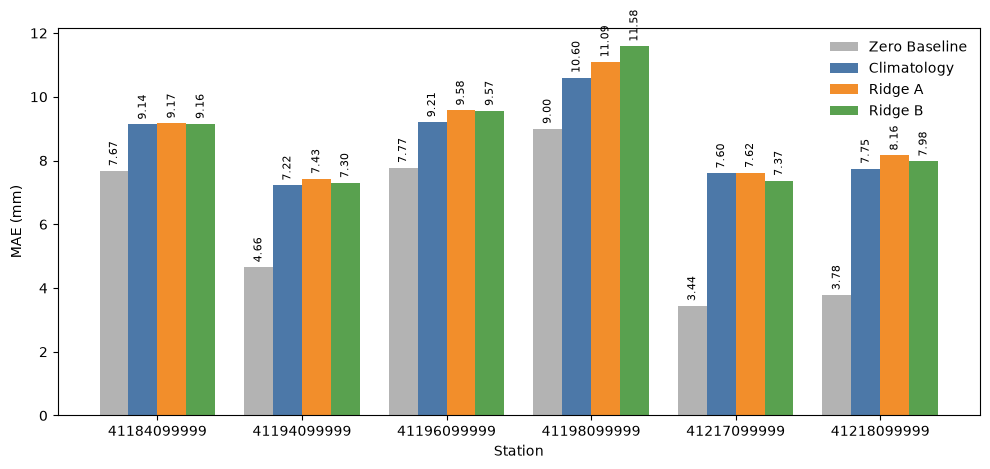

In [51]:
plot_df = mae_comparison.copy()

stations = plot_df.index.astype(str).tolist()
x = np.arange(len(stations))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 4.8))

bars1 = ax.bar(
    x - 1.5 * width,
    plot_df["Zero Baseline"],
    width,
    label="Zero Baseline",
    color="0.7"
)

bars2 = ax.bar(
    x - 0.5 * width,
    plot_df["Climatology"],
    width,
    label="Climatology",
    color="#4C78A8"
)

bars3 = ax.bar(
    x + 0.5 * width,
    plot_df["Ridge A"],
    width,
    label="Ridge A",
    color="#F28E2B"
)

bars4 = ax.bar(
    x + 1.5 * width,
    plot_df["Ridge B"],
    width,
    label="Ridge B",
    color="#59A14F"
)

ax.set_xlabel("Station")
ax.set_ylabel("MAE (mm)")
ax.set_xticks(x)
ax.set_xticklabels(stations)
ax.legend(frameon=False)

# value labels
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.15,
            f"{h:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

fig.tight_layout()
save_figure(fig, "station_level_mae_comparison")
plt.show()

Figure 2. Station-level mean absolute error (MAE) of the zero-rainfall baseline, calendar-month climatology, and Ridge regression using Feature Sets A and B under nested leave-one-station-out evaluation across six UAE weather stations. Lower values indicate better performance.

Figures 1 and 2 present the station-level RMSE and MAE under nested leave-one-station-out evaluation. Calendar-month climatology achieved the lowest station-averaged RMSE (19.6427 mm), outperforming Ridge regression with Feature Set A (19.8181 mm) and Feature Set B (19.8165 mm). In contrast, the zero-rainfall baseline achieved the lowest station-averaged MAE (6.0550 mm) and outperformed all other methods at every held-out station in terms of MAE. These findings highlight the influence of rainfall sparsity on evaluation outcomes. Although including historical rainfall features produced modest improvements in Ridge regression, these improvements were insufficient to consistently outperform the seasonal climatology baseline. The results suggest that model complexity does not necessarily translate into stronger cross-station generalization under the evaluated conditions.

In [53]:
r2_comparison = (
    ridge_results_df
    .pivot(
        index="station",
        columns="feature_set",
        values="r2"
    )
    .rename(columns={
        "A": "Ridge A",
        "B": "Ridge B"
    })
)

r2_comparison["B_minus_A"] = (r2_comparison["Ridge B"] - r2_comparison["Ridge A"])

display(r2_comparison.round(4))

print("Mean R² — Set A:", round(r2_comparison["Ridge A"].mean(), 4))
print("Mean R² — Set B:", round(r2_comparison["Ridge B"].mean(), 4))

print("Stations with positive R² — A:", (r2_comparison["Ridge A"] > 0).sum())
print("Stations with positive R² — B:", (r2_comparison["Ridge B"] > 0).sum())



feature_set,Ridge A,Ridge B,B_minus_A
station,,,
41184099999,0.0526,0.0597,0.0071
41194099999,0.0663,0.0659,-0.0004
41196099999,0.0214,0.0313,0.0099
41198099999,0.0068,-0.0076,-0.0144
41217099999,-0.0362,-0.0319,0.0042
41218099999,-0.0436,-0.0352,0.0084


Mean R² — Set A: 0.0112
Mean R² — Set B: 0.0137
Stations with positive R² — A: 4
Stations with positive R² — B: 3


In [54]:
from pathlib import Path

RESULTS_DIR = PROJECT_ROOT / "results" / "tables"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ridge_results_df.to_csv(
    RESULTS_DIR / "ridge_seasonal_loso_results.csv",
    index=False
)

# Save inner LOSO hyperparameter tuning
ridge_tuning_df.to_csv(
    RESULTS_DIR / "ridge_seasonal_loso_tuning.csv",
    index=False
)

# Save baseline results
climatology_df.to_csv(
    RESULTS_DIR / "calendar_month_climatology_results.csv",
    index=False
)

# Save main comparison
main_results.to_csv(
    RESULTS_DIR / "ridge_baseline_comparison.csv",
    index=False
)

print("Research result tables saved successfully.")
for path in sorted(RESULTS_DIR.glob("*.csv")):
    print(path.name)


Research result tables saved successfully.
calendar_month_climatology_results.csv
ridge_baseline_comparison.csv
ridge_seasonal_loso_results.csv
ridge_seasonal_loso_tuning.csv
